# 13 — Hierarchical Clustering

> Building a whole family tree of groups, from single points up to one cluster, and choosing where to cut it afterwards.

The summary of this lesson is in [README.md](README.md). This notebook is the
full working: the reasoning, the code, and the results.

**Contents**

1. The problem
2. Intuition
3. The mathematics
4. Hierarchical clustering on generated data
5. Clustering vehicles
6. What the clusters are
7. References

## 1. The problem

Lesson 12's k-means needed the number of clusters before it started, and gave
back one flat answer. Often neither suits the question. A car manufacturer
planning a new model does not know in advance whether the market has four kinds
of vehicle or nine — it wants to see how vehicles group at every level of
detail, then decide.

- **Input:** rows of features, with no labels
- **Output:** a tree of nested groupings — and, after cutting the tree, a cluster
  number for each row
- **A good answer** merges similar vehicles early and dissimilar ones late, so
  that every level of the tree is a sensible grouping.

## 2. Intuition

**Agglomerative** hierarchical clustering works from the bottom up:

1. Start with every point as its own cluster.
2. Find the two clusters that are closest together and merge them.
3. Repeat until everything is one cluster.

With $n$ points that takes exactly $n - 1$ merges, and the record of those
merges is a tree — a **dendrogram**. Leaves are the individual points; each
joint is a merge, drawn at the height of the distance at which it happened.

Cutting the dendrogram with a horizontal line gives a flat clustering: every
branch the line crosses becomes one cluster. Cut low, and there are many small
tight clusters; cut high, and there are a few broad ones. **The number of
clusters is chosen after the algorithm has run, by looking at the tree** — the
main thing k-means could not offer.

(The opposite, *divisive* approach starts with one cluster and splits it. It is
used far less, and is not covered here.)

## 3. The mathematics

Merging "the two closest clusters" needs a definition of distance between two
**groups** of points. That definition is the **linkage**. For clusters $A$ and
$B$, with $d(a, b)$ the distance between two points:

| Linkage | Distance between $A$ and $B$ | Tends to produce |
|---|---|---|
| Single | $\min_{a \in A,\, b \in B} d(a, b)$ — the closest pair | long chains; one stray point can join two groups |
| Complete | $\max_{a \in A,\, b \in B} d(a, b)$ — the farthest pair | compact clusters of similar diameter |
| Average | $\dfrac{1}{\lvert A\rvert \lvert B\rvert} \sum_{a \in A} \sum_{b \in B} d(a, b)$ | a compromise between the two |
| Ward | the increase in total within-cluster variance caused by merging | round clusters — the k-means objective, built bottom-up |

The height of each joint in the dendrogram is this linkage distance at the
moment of the merge, so a long vertical gap above a group means that group was
far from everything else before it merged — a natural place to cut.

**The distance matrix.** Every merge decision uses distances between points,
so they are computed once up front: an $n \times n$ matrix $D$ with
$D_{ij} = d(x_i, x_j)$. It is symmetric with zeros on the diagonal, so only the
$\tfrac{n(n-1)}{2}$ entries above the diagonal carry information. SciPy's
`linkage` expects exactly those, as a flat **condensed** vector, which
`squareform` produces from the square matrix.

**The cost.** The matrix alone holds $n^2$ numbers, and the merging repeats over
it $n - 1$ times. That is comfortable for a few thousand rows and impractical
for millions — the price of getting the whole tree rather than one answer.

## 4. Hierarchical clustering on generated data

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.cluster import hierarchy
from scipy.spatial import distance_matrix
from scipy.spatial.distance import squareform
import scipy.spatial.distance
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import make_blobs

50 points around four centres — $(4, 4)$, $(-2, -1)$, $(1, 1)$ and $(10, 4)$ —
with standard deviation 0.9. `random_state=0` fixes the points so every run
produces the same data.

In [2]:
X1, y1 = make_blobs(n_samples=50, centers=[[4,4], [-2, -1], [1, 1], [10,4]], cluster_std=0.9, random_state=0)

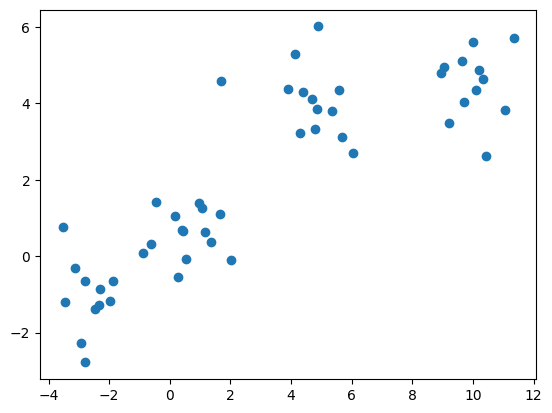

In [3]:
plt.scatter(X1[:, 0], X1[:, 1], marker='o')
plt.show()

### Agglomerative clustering with scikit-learn

`n_clusters=4` cuts the tree where four branches remain, and
`linkage='average'` measures the distance between two clusters as the average
over all pairs of their points.

`fit` is given only `X1`. The true groups in `y1` are never shown to the
algorithm — clustering has no labels to learn from — but they are kept so the
result can be checked.

In [4]:
agglom = AgglomerativeClustering(n_clusters = 4, linkage = 'average')

In [5]:
agglom.fit(X1)

AgglomerativeClustering(linkage='average', n_clusters=4)

In the plot below, each point is drawn as the **number of the true group** it
came from, and **coloured by the cluster** the algorithm assigned. If the
clustering is right, every number of one value should share one colour. (The
cluster numbers and the true numbers need not match — only the grouping
matters.)

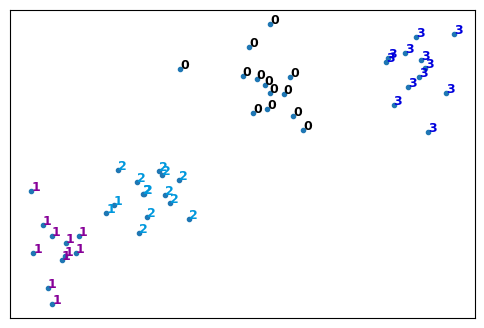

In [6]:
# Create a figure of size 6 inches by 4 inches.
plt.figure(figsize=(6,4))

# These two lines of code are used to scale the data points down,
# Or else the data points will be scattered very far apart.

# Create a minimum and maximum range of X1.
x_min, x_max = np.min(X1, axis=0), np.max(X1, axis=0)

# Get the average distance for X1.
X1 = (X1 - x_min) / (x_max - x_min)

# This loop displays all of the datapoints.
for i in range(X1.shape[0]):
    # Replace the data points with their respective cluster value
    # (ex. 0) and is color coded with a colormap (plt.cm.spectral)
    plt.text(X1[i, 0], X1[i, 1], str(y1[i]),
             color=plt.cm.nipy_spectral(agglom.labels_[i] / 10.),
             fontdict={'weight': 'bold', 'size': 9})

# Remove the x ticks, y ticks, x and y axis
plt.xticks([])
plt.yticks([])
#plt.axis('off')



# Display the plot of the original data before clustering
plt.scatter(X1[:, 0], X1[:, 1], marker='.')
# Display the plot
plt.show()

Note that this cell also **rescales `X1` to the range 0–1 on each axis** and
keeps the result. Everything from here to the end of section 4 uses the
rescaled points. Because the two axes are stretched by different amounts, the
distances change, so the dendrograms below are built from slightly different
geometry than the scikit-learn clustering above.

### The dendrogram

First the distance matrix: the distance from every point to every other point.

In [7]:
dist_matrix = distance_matrix(X1,X1)
print(dist_matrix)

[[0.         0.89221967 0.08362736 ... 0.38011012 0.78910769 0.77496568]
 [0.89221967 0.         0.93347579 ... 0.55895655 0.18458274 0.12494651]
 [0.08362736 0.93347579 0.         ... 0.39635751 0.84286948 0.8202518 ]
 ...
 [0.38011012 0.55895655 0.39635751 ... 0.         0.5119048  0.46018236]
 [0.78910769 0.18458274 0.84286948 ... 0.5119048  0.         0.10318462]
 [0.77496568 0.12494651 0.8202518  ... 0.46018236 0.10318462 0.        ]]


The diagonal is zero — every point is at distance 0 from itself — and the matrix
is symmetric. `squareform` turns it into the condensed form `linkage` expects,
and `'complete'` measures the distance between clusters by their farthest pair
of points.

In [8]:
Z = hierarchy.linkage(squareform(dist_matrix), 'complete')

Each U-shaped joint is a merge, drawn at the height of the distance at which it
happened. Reading from the bottom up replays the algorithm.

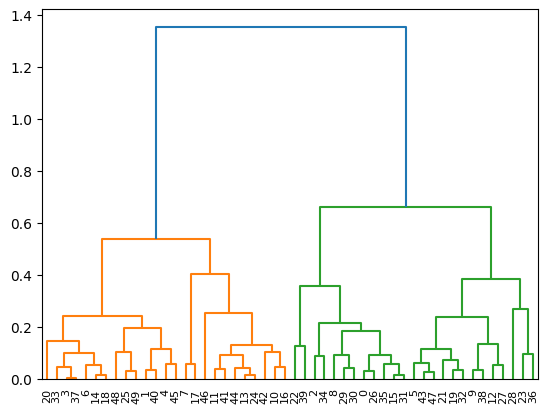

In [9]:
dendro = hierarchy.dendrogram(Z)
plt.savefig('figures/dendrogram_complete.png', dpi=150, bbox_inches='tight')
plt.show()

The same tree with **average** linkage, for comparison:

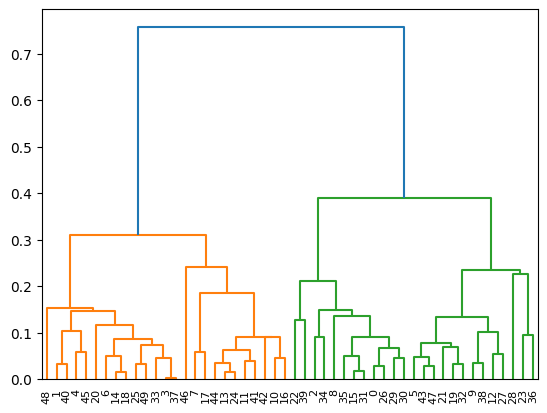

In [10]:
Z = hierarchy.linkage(squareform(dist_matrix), 'average')
dendro = hierarchy.dendrogram(Z)
plt.show()

Cut where four branches remain, both trees give the same grouping as
scikit-learn did above: **48 of the 50 points land with their true group.** The
two exceptions come from the group around $(-2, -1)$ and are placed with the
group around $(1, 1)$ — the two centres closest together, whose points overlap.

The difference between the linkages is in the heights. Complete linkage measures
a cluster by its farthest pair, so its merge heights grow quickly as clusters
get bigger — the final merge happens at about 1.35 here, against about 0.76 for
average linkage.

Reading the complete-linkage tree honestly, the largest vertical gap is the one
just below the final merge, from about 0.66 up to 1.35. If the cut were chosen
from the tree alone, it would suggest **two** broad groups, not four. The
dendrogram shows every possible answer; which one is right depends on how fine
a distinction the question needs.

## 5. Clustering vehicles

A manufacturer has a prototype for a new vehicle and wants to know which
existing models it would compete against. Grouping the vehicles already on the
market by their physical specifications answers that: the prototype's
competitors are the vehicles in the group it would fall into.

In [11]:
#Read csv
pdf = pd.read_csv("data/cars_clus.csv")
print ("Shape of dataset: ", pdf.shape)

pdf.head(5)

Shape of dataset:  (159, 16)


,manufact,model,sales,resale,type,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,lnsales,partition
0,Acura,Integra,16.919,16.360,0.000,21.500,1.800,140.000,101.200,67.300,172.400,2.639,13.200,28.000,2.828,0.0
1,Acura,TL,39.384,19.875,0.000,28.400,3.200,225.000,108.100,70.300,192.900,3.517,17.200,25.000,3.673,0.0
2,Acura,CL,14.114,18.225,0.000,$null$,3.200,225.000,106.900,70.600,192.000,3.470,17.200,26.000,2.647,0.0
3,Acura,RL,8.588,29.725,0.000,42.000,3.500,210.000,114.600,71.400,196.600,3.850,18.000,22.000,2.150,0.0
4,Audi,A4,20.397,22.255,0.000,23.990,1.800,150.000,102.600,68.200,178.000,2.998,16.400,27.000,3.015,0.0


The columns used here are price in thousands of dollars (`price`), engine size
in litres (`engine_s`), horsepower (`horsepow`), wheelbase (`wheelbas`), width,
length, curb weight in thousands of pounds (`curb_wgt`), fuel capacity
(`fuel_cap`) and fuel efficiency in miles per gallon (`mpg`). `type` is 0 for a
car and 1 for a truck.

### Data cleaning

In [12]:
pdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 16 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   manufact   157 non-null    object 
 1   model      159 non-null    object 
 2   sales      159 non-null    object 
 3   resale     159 non-null    object 
 4   type       159 non-null    object 
 5   price      159 non-null    object 
 6   engine_s   159 non-null    object 
 7   horsepow   159 non-null    object 
 8   wheelbas   159 non-null    object 
 9   width      159 non-null    object 
 10  length     159 non-null    object 
 11  curb_wgt   159 non-null    object 
 12  fuel_cap   159 non-null    object 
 13  mpg        159 non-null    object 
 14  lnsales    159 non-null    object 
 15  partition  159 non-null    float64
dtypes: float64(1), object(15)
memory usage: 20.0+ KB


In [13]:
pdf.isnull().sum()

manufact     2
model        0
sales        0
resale       0
type         0
price        0
engine_s     0
horsepow     0
wheelbas     0
width        0
length       0
curb_wgt     0
fuel_cap     0
mpg          0
lnsales      0
partition    0
dtype: int64

`isnull` finds only two missing manufacturer names, but `info` shows the
numeric columns were read as text. Missing values in this file are written as
the string `$null$` (visible in the third row above), which pandas does not
recognise as missing. Converting the columns to numbers turns those strings into
real missing values, and the rows that contain any are dropped.

In [14]:
print ("Shape of dataset before cleaning: ", pdf.shape)
pdf[[ 'sales', 'resale', 'type', 'price', 'engine_s',
       'horsepow', 'wheelbas', 'width', 'length', 'curb_wgt', 'fuel_cap',
       'mpg', 'lnsales']] = pdf[['sales', 'resale', 'type', 'price', 'engine_s',
       'horsepow', 'wheelbas', 'width', 'length', 'curb_wgt', 'fuel_cap',
       'mpg', 'lnsales']].apply(pd.to_numeric, errors='coerce')
pdf = pdf.dropna()
pdf = pdf.reset_index(drop=True)
print ("Shape of dataset after cleaning: ", pdf.shape)
pdf.head(5)

Shape of dataset before cleaning:  (159, 16)
Shape of dataset after cleaning:  (117, 16)


,manufact,model,sales,resale,type,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,lnsales,partition
0,Acura,Integra,16.919,16.360,0.0,21.50,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,2.828,0.0
1,Acura,TL,39.384,19.875,0.0,28.40,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,3.673,0.0
2,Acura,RL,8.588,29.725,0.0,42.00,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,2.150,0.0
3,Audi,A4,20.397,22.255,0.0,23.99,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,3.015,0.0
4,Audi,A6,18.780,23.555,0.0,33.95,2.8,200.0,108.7,76.1,192.0,3.561,18.5,22.0,2.933,0.0


In [15]:
pdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Data columns (total 16 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   manufact   117 non-null    object 
 1   model      117 non-null    object 
 2   sales      117 non-null    float64
 3   resale     117 non-null    float64
 4   type       117 non-null    float64
 5   price      117 non-null    float64
 6   engine_s   117 non-null    float64
 7   horsepow   117 non-null    float64
 8   wheelbas   117 non-null    float64
 9   width      117 non-null    float64
 10  length     117 non-null    float64
 11  curb_wgt   117 non-null    float64
 12  fuel_cap   117 non-null    float64
 13  mpg        117 non-null    float64
 14  lnsales    117 non-null    float64
 15  partition  117 non-null    float64
dtypes: float64(14), object(2)
memory usage: 14.8+ KB


159 vehicles become 117 with every value present.

### Feature selection

Eight physical specifications describe each vehicle. `price` and `type` are
deliberately left out, so that they can be used afterwards to check whether the
clusters mean anything.

In [16]:
featureset = pdf[['engine_s',  'horsepow', 'wheelbas', 'width', 'length', 'curb_wgt', 'fuel_cap', 'mpg']]

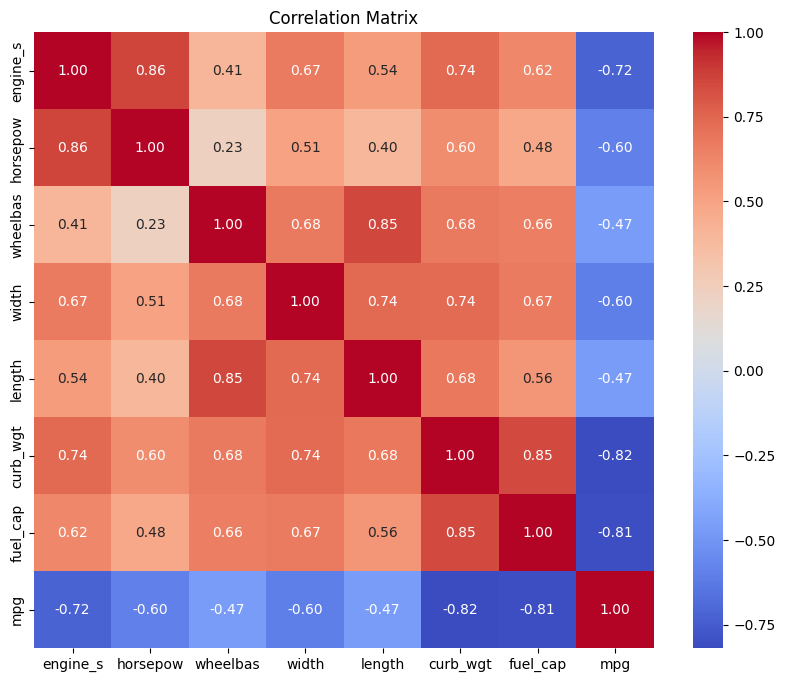

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = featureset.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Matrix')
plt.show()

The features are heavily correlated. Engine size, horsepower, weight, size and
fuel capacity all rise together, and `mpg` falls as they rise — they are largely
different measurements of one underlying quantity: how big and powerful the
vehicle is. Clustering on all eight therefore gives that dimension a lot of
weight.

### Normalisation

Horsepower runs into the hundreds while engine size is a few litres. Without
rescaling, horsepower would dominate every distance. `MinMaxScaler` maps each
feature to the range 0–1, so all eight contribute on the same scale.

In [18]:
from sklearn.preprocessing import MinMaxScaler
x = featureset.values #returns a numpy array
min_max_scaler = MinMaxScaler()
feature_mtx = min_max_scaler.fit_transform(x)
feature_mtx [0:5]

array([[0.11428571, 0.21518987, 0.18655098, 0.28143713, 0.30625832,
        0.2310559 , 0.13364055, 0.43333333],
       [0.31428571, 0.43037975, 0.3362256 , 0.46107784, 0.5792277 ,
        0.50372671, 0.31797235, 0.33333333],
       [0.35714286, 0.39240506, 0.47722343, 0.52694611, 0.62849534,
        0.60714286, 0.35483871, 0.23333333],
       [0.11428571, 0.24050633, 0.21691974, 0.33532934, 0.38082557,
        0.34254658, 0.28110599, 0.4       ],
       [0.25714286, 0.36708861, 0.34924078, 0.80838323, 0.56724368,
        0.5173913 , 0.37788018, 0.23333333]])

### The distance matrix, computed by hand

The distance between every pair of vehicles, written out as two loops — exactly
the $D_{ij} = d(x_i, x_j)$ of section 3.

In [19]:
leng = feature_mtx.shape[0]
D = np.zeros([leng,leng])
for i in range(leng):
    for j in range(leng):
        D[i,j] = scipy.spatial.distance.euclidean(feature_mtx[i], feature_mtx[j])
D

array([[0.        , 0.57777143, 0.75455727, ..., 0.28530295, 0.24917241,
        0.18879995],
       [0.57777143, 0.        , 0.22798938, ..., 0.36087756, 0.66346677,
        0.62201282],
       [0.75455727, 0.22798938, 0.        , ..., 0.51727787, 0.81786095,
        0.77930119],
       ...,
       [0.28530295, 0.36087756, 0.51727787, ..., 0.        , 0.41797928,
        0.35720492],
       [0.24917241, 0.66346677, 0.81786095, ..., 0.41797928, 0.        ,
        0.15212198],
       [0.18879995, 0.62201282, 0.77930119, ..., 0.35720492, 0.15212198,
        0.        ]])

### The same thing with scikit-learn

`euclidean_distances` produces the same matrix in one call.

In [20]:
from sklearn.metrics.pairwise import euclidean_distances
dist_matrix = euclidean_distances(feature_mtx,feature_mtx)
print(dist_matrix)

[[0.         0.57777143 0.75455727 ... 0.28530295 0.24917241 0.18879995]
 [0.57777143 0.         0.22798938 ... 0.36087756 0.66346677 0.62201282]
 [0.75455727 0.22798938 0.         ... 0.51727787 0.81786095 0.77930119]
 ...
 [0.28530295 0.36087756 0.51727787 ... 0.         0.41797928 0.35720492]
 [0.24917241 0.66346677 0.81786095 ... 0.41797928 0.         0.15212198]
 [0.18879995 0.62201282 0.77930119 ... 0.35720492 0.15212198 0.        ]]


In [21]:
Z_using_dist_matrix = hierarchy.linkage(squareform(dist_matrix, checks=False), 'complete')

`checks=False` skips `squareform`'s test that the matrix is exactly symmetric
with an exactly zero diagonal. Floating-point arithmetic can leave differences
of around $10^{-16}$, which are harmless but would fail an exact test.

The full dendrogram, with every leaf labelled as *manufacturer, model, type*:

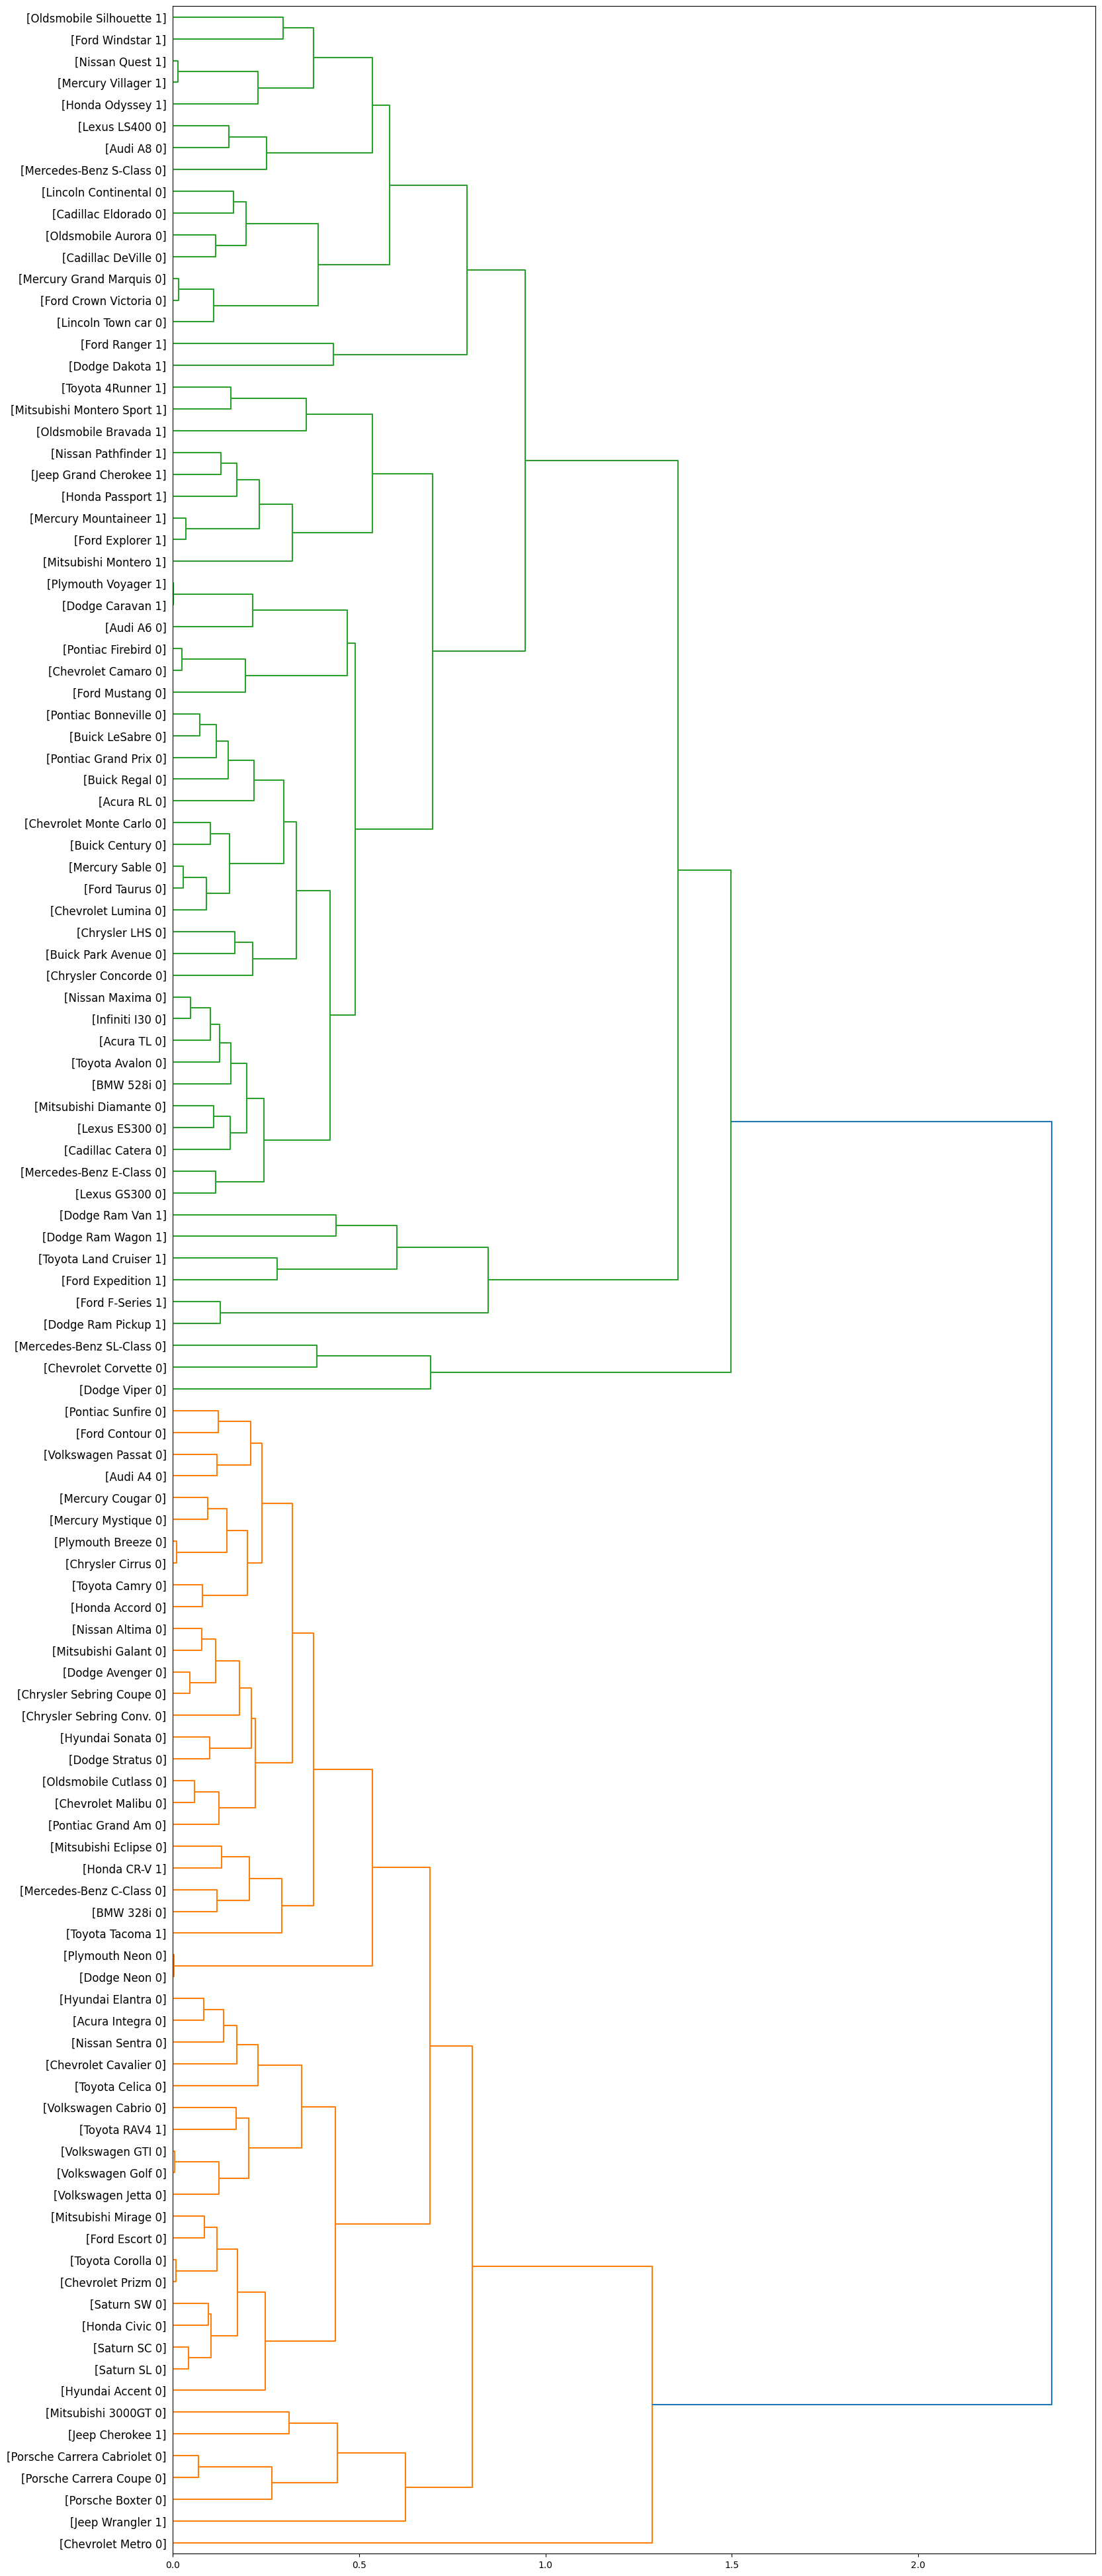

In [22]:
fig = plt.figure(figsize=(18,50))
def llf(id):
    return '[%s %s %s]' % (pdf['manufact'][id], pdf['model'][id], int(float(pdf['type'][id])) )

dendro = hierarchy.dendrogram(Z_using_dist_matrix,  leaf_label_func=llf, leaf_rotation=0, leaf_font_size =12, orientation = 'right')

Reading the leaves from the bottom, neighbouring vehicles are the ones that
merged earliest: closely matched models from different manufacturers sit side
by side, and the long branches on the right show where the broad groups join.

### Cutting the tree with scikit-learn

`AgglomerativeClustering` with `n_clusters=6` builds the same complete-linkage
tree and cuts it where six branches remain. `metric='precomputed'` tells it the
input is already a distance matrix — without it, scikit-learn would treat each
row of distances as a list of features and cluster the wrong thing.

In [23]:
agglom = AgglomerativeClustering(n_clusters = 6, linkage = 'complete', metric = 'precomputed')
agglom.fit(dist_matrix)

agglom.labels_

array([1, 2, 2, 1, 2, 3, 1, 2, 2, 2, 2, 2, 3, 3, 2, 1, 1, 2, 2, 2, 5, 1,
       4, 1, 1, 2, 1, 2, 1, 1, 1, 5, 0, 0, 0, 3, 2, 1, 2, 1, 2, 3, 2, 3,
       0, 3, 0, 1, 1, 1, 2, 3, 1, 1, 1, 2, 1, 1, 2, 2, 2, 3, 3, 3, 1, 1,
       1, 2, 1, 2, 2, 1, 1, 2, 3, 2, 3, 1, 2, 3, 5, 1, 1, 2, 3, 2, 1, 3,
       2, 3, 1, 1, 2, 1, 1, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1,
       2, 0, 1, 1, 1, 1, 1], dtype=int64)

Each vehicle's cluster is added to the table:

In [24]:
pdf['cluster_'] = agglom.labels_
pdf.head()

,manufact,model,sales,resale,type,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,lnsales,partition,cluster_
0,Acura,Integra,16.919,16.360,0.0,21.50,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,2.828,0.0,1
1,Acura,TL,39.384,19.875,0.0,28.40,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,3.673,0.0,2
2,Acura,RL,8.588,29.725,0.0,42.00,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,2.150,0.0,2
3,Audi,A4,20.397,22.255,0.0,23.99,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,3.015,0.0,1
4,Audi,A6,18.780,23.555,0.0,33.95,2.8,200.0,108.7,76.1,192.0,3.561,18.5,22.0,2.933,0.0,2


Horsepower against fuel efficiency, with each vehicle coloured by cluster and
sized by price:

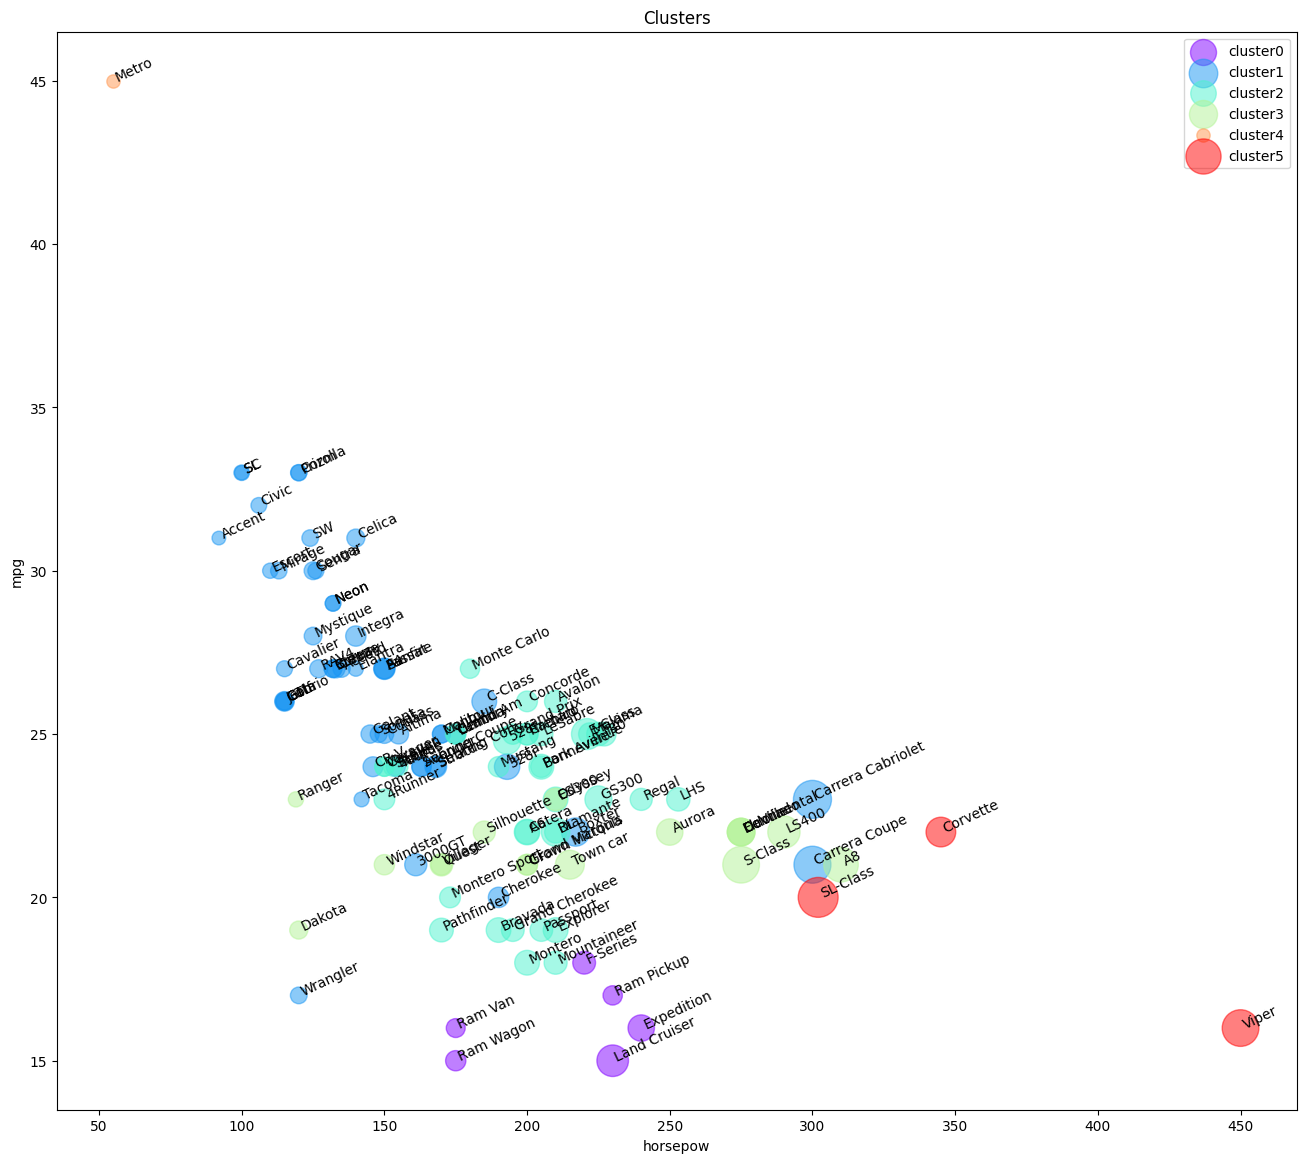

In [25]:
import matplotlib.cm as cm
n_clusters = max(agglom.labels_)+1
colors = cm.rainbow(np.linspace(0, 1, n_clusters))
cluster_labels = list(range(0, n_clusters))

# Create a figure of size 16 inches by 14 inches.
plt.figure(figsize=(16,14))

for color, label in zip(colors, cluster_labels):
    subset = pdf[pdf.cluster_ == label]
    for i in subset.index:
            plt.text(subset.horsepow[i], subset.mpg[i],str(subset['model'][i]), rotation=25)
    plt.scatter(subset.horsepow, subset.mpg, s= subset.price*10, color=color, label='cluster'+str(label),alpha=0.5)
#    plt.scatter(subset.horsepow, subset.mpg)
plt.legend()
plt.title('Clusters')
plt.xlabel('horsepow')
plt.ylabel('mpg')
plt.savefig('figures/result.png', dpi=150, bbox_inches='tight')
plt.show()

### Summarising the clusters

The scatter shows where each cluster lies but not its centre. The dataset holds
two kinds of vehicle — cars (`type` 0) and trucks (`type` 1) — so each cluster
is summarised separately for each. First, how many of each:

In [26]:
pdf.groupby(['cluster_','type'])['cluster_'].count()

cluster_  type
0         1.0      6
1         0.0     47
          1.0      5
2         0.0     27
          1.0     11
3         0.0     10
          1.0      7
4         0.0      1
5         0.0      3
Name: cluster_, dtype: int64

Then the average specifications of each group:

In [27]:
agg_cars = pdf.groupby(['cluster_','type'])[['horsepow','engine_s','mpg','price']].mean()
agg_cars

horsepow  engine_s        mpg      price
cluster_ type                                            
0        1.0   211.666667  4.483333  16.166667  29.024667
1        0.0   146.531915  2.246809  27.021277  20.306128
         1.0   145.000000  2.580000  22.200000  17.009200
2        0.0   203.111111  3.303704  24.214815  27.750593
         1.0   182.090909  3.345455  20.181818  26.265364
3        0.0   256.500000  4.410000  21.500000  42.870400
         1.0   160.571429  3.071429  21.428571  21.527714
4        0.0    55.000000  1.000000  45.000000   9.235000
5        0.0   365.666667  6.233333  19.333333  66.010000

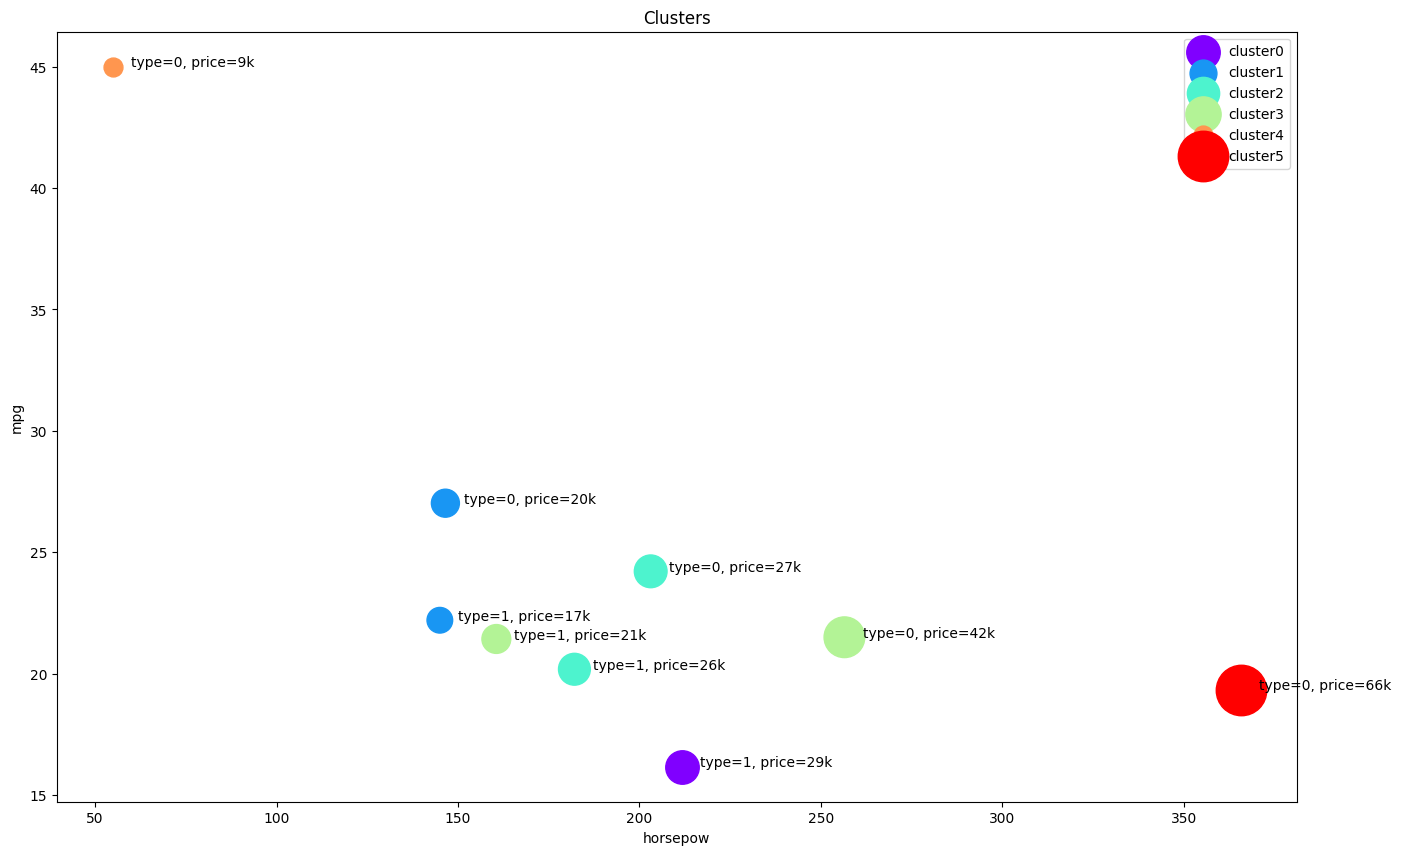

In [28]:
plt.figure(figsize=(16,10))
for color, label in zip(colors, cluster_labels):
    subset = agg_cars.loc[(label,),]
    for i in subset.index:
        plt.text(subset.loc[i].iloc[0]+5, subset.loc[i].iloc[2], 'type='+str(int(i)) + ', price='+str(int(subset.loc[i].iloc[3]))+'k')
    plt.scatter(subset.horsepow, subset.mpg, s=subset.price*20, color=color, label='cluster'+str(label))
plt.legend()
plt.title('Clusters')
plt.xlabel('horsepow')
plt.ylabel('mpg')
plt.show()

## 6. What the clusters are

From the two tables above:

| Cluster | Vehicles | Typical models | Horsepower | Engine (L) | mpg | Price ($k) |
|---|---|---|---|---|---|---|
| 4 | 1 car | Metro | 55 | 1.0 | 45.0 | 9.2 |
| 1 | 47 cars, 5 trucks | Integra, A4, Cavalier, Malibu | 146 | 2.2 | 27.0 | 20.3 |
| 2 | 27 cars, 11 trucks | TL, A6, 528i, Century | 203 | 3.3 | 24.2 | 27.8 |
| 3 | 10 cars, 7 trucks | A8, DeVille, Crown Victoria, Dakota | 257 | 4.4 | 21.5 | 42.9 |
| 5 | 3 cars | Corvette, Viper, SL-Class | 366 | 6.2 | 19.3 | 66.0 |
| 0 | 6 trucks | Ram, F-Series, Expedition, Land Cruiser | 212 | 4.5 | 16.2 | 29.0 |

(Figures for mixed clusters are for their cars.)

Read in order, clusters 4 → 1 → 2 → 3 → 5 form a ladder: each step up has more
power, a bigger engine, worse fuel economy — and **a higher price**. Price was
never shown to the algorithm. The clusters were built from physical
specifications alone, and they still rank the market from \$9k to \$66k. That is
the best evidence that the grouping is real rather than an artefact of the
method.

Cluster 0 sits off the ladder: the full-size trucks and SUVs, with moderate
power but the worst fuel economy of any group, because they are heavy rather
than fast.

**Size outvotes power.** Five of the eight features — wheelbase, width,
length, curb weight and fuel capacity — describe how big a vehicle is, and only
two describe its engine. The clearest consequence is visible in the scatter: the
Porsche Carrera Coupé and Cabriolet, at 300 horsepower, sit in cluster 1 with
the economy cars, because they are small and light. Choosing the features is
choosing what "similar" means.

**Type is a different story.** Trucks appear in four of the six clusters, so the
specifications do not separate cars from trucks — a minivan or a compact pickup
has more in common with a mid-size car than with an F-Series. Only the heaviest
trucks form a group of their own.

**Two of the six clusters are tiny.** The Metro is alone, and the three sports
cars form a group of three. Complete linkage measures a cluster by its farthest
pair, so a vehicle unlike everything else stays apart until near the top of the
tree. That is useful — it flags the outliers — but it means six clusters is
really four main groups and two special cases. A different cut of the
dendrogram would give a different answer, and choosing it is a judgement, not
a calculation.

## 7. References

- Dataset: vehicle specifications (`cars_clus.csv`), as supplied with the course.
- Course: Machine Learning with Python (Jadi), based on the IBM / Cognitive Class
  hierarchical clustering lab.
- Müllner, D. (2011). *Modern Hierarchical, Agglomerative Clustering
  Algorithms*. arXiv:1109.2378.
- [SciPy: `scipy.cluster.hierarchy`](https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html)
- [scikit-learn: Hierarchical clustering](https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering)